# Patient-level triage for urogenital schistosomiasis

The Schistoscope takes 117 images per urine sample and calls a patient
positive if an egg is found in any one of them. That rule gives 48.9%
specificity — half of healthy patients are told they are infected.

The weak step is **aggregation**: turning 117 image results into one
patient decision.

This notebook sets out to answer three questions about that step:

1. Does a learned aggregator beat parameter-free pooling at n = 65?
2. Does a finer representation — tiles rather than whole frames — help?
3. How much of the bag should a decision draw on?

Every split is over **patients**, never images.

## 1 · Fetch and verify the data

The dataset is 65 patient samples from Zenodo, each photographed 117 times.
Rather than trust a copy, the archive is downloaded here, checked against
its published MD5, and its structure asserted before anything is modelled.

In [8]:
import requests, shutil

REC = "6467268"          # Zenodo record for the Schistosoma haematobium egg dataset

r = requests.get(f"https://zenodo.org/api/records/{REC}", timeout=60)
r.raise_for_status()
rec = r.json()

print(rec["metadata"]["title"])
print(rec["metadata"]["license"]["id"], "\n")

for f in rec["files"]:
    print(f"{f['key']:50s} {f['size']/1e9:6.2f} GB  {f['checksum']}")

total, used, free = shutil.disk_usage("/kaggle/working")
print(f"\ndisk free: {free/1e9:.1f} GB")

Schistosoma Haematobium Egg Image Dataset
cc-by-4.0 

SHdataset_12k.zip                                   27.81 GB  md5:2bf5c9d6f481dc85ee2809c0f98d6b48
diagnosis_test_dataset.zip                          12.52 GB  md5:76c20a6c5f566c2f141b6dd274ea4d74

disk free: 20.9 GB


### Download

The archive is 12.5 GB. A single-stream download runs at roughly 1 MB/s from
this region, so the file is fetched in sixteen parallel byte-range requests
and reassembled in place, then checked against the MD5 published above.

In [9]:
import hashlib, pathlib, threading
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.auto import tqdm

TARGET   = "diagnosis_test_dataset.zip"
WORK     = pathlib.Path("/kaggle/working")
ZIP_PATH = WORK / TARGET

meta     = next(f for f in rec["files"] if f["key"] == TARGET)
SRC_URL  = meta["links"]["self"]
TOTAL    = meta["size"]
MD5_PUB  = meta["checksum"].split(":")[1]

N_CONN, RETRIES, CHUNK = 16, 4, 4 * 1024 * 1024

with open(ZIP_PATH, "wb") as f:
    f.truncate(TOTAL)

bar  = tqdm(total=TOTAL, unit="B", unit_scale=True, unit_divisor=1024, desc="download")
lock = threading.Lock()

def fetch_range(start, end):
    for attempt in range(RETRIES):
        pos = start
        try:
            hdrs = {"Range": f"bytes={pos}-{end}"}
            with requests.get(SRC_URL, headers=hdrs, stream=True,
                              allow_redirects=True, timeout=(30, 300)) as resp:
                if resp.status_code != 206:
                    raise RuntimeError(f"expected 206, got {resp.status_code}")
                with open(ZIP_PATH, "r+b") as f:
                    f.seek(pos)
                    for chunk in resp.iter_content(chunk_size=CHUNK):
                        if not chunk:
                            continue
                        f.write(chunk)
                        pos += len(chunk)
                        with lock:
                            bar.update(len(chunk))
            if pos - 1 == end:
                return True, None
            raise RuntimeError(f"short segment: {pos-start} of {end-start+1}")
        except Exception as e:
            with lock:
                bar.update(-(pos - start))
            if attempt == RETRIES - 1:
                return False, f"{type(e).__name__}: {e}"
    return False, "exhausted retries"

seg    = TOTAL // N_CONN
ranges = [(i * seg, (TOTAL - 1) if i == N_CONN - 1 else (i + 1) * seg - 1)
          for i in range(N_CONN)]

with ThreadPoolExecutor(max_workers=N_CONN) as ex:
    futures = [ex.submit(fetch_range, s, e) for s, e in ranges]
    for fut in as_completed(futures):
        ok, err = fut.result()
        assert ok, f"segment failed: {err}"
bar.close()

h = hashlib.md5()
with open(ZIP_PATH, "rb") as f:
    for block in iter(lambda: f.read(8 * 1024 * 1024), b""):
        h.update(block)

print("published:", MD5_PUB)
print("computed :", h.hexdigest())
assert h.hexdigest() == MD5_PUB, "MD5 MISMATCH — archive is corrupt"
print(f"\nverified · {ZIP_PATH.stat().st_size/1e9:.2f} GB")

download:   0%|          | 0.00/11.7G [00:00<?, ?B/s]

published: 76c20a6c5f566c2f141b6dd274ea4d74
computed : 76c20a6c5f566c2f141b6dd274ea4d74

verified · 12.52 GB


### Inspect the archive

Before extracting anything, the archive's structure is read from its index —
how many entries, how they are organised, what the patient folders look like.
Cheap to do, and it means the extraction code is written against what is
actually there rather than what was assumed.

In [10]:
import zipfile, collections, re

zf = zipfile.ZipFile(ZIP_PATH)
names = zf.namelist()

print(f"{len(names):,} entries in archive\n")

print("first 15 entries:")
for n in names[:15]:
    print("  ", n)

exts = collections.Counter(pathlib.PurePosixPath(n).suffix.lower() for n in names)
print("\nfile types:", dict(exts))

depths = collections.Counter(n.rstrip("/").count("/") for n in names)
print("path depths:", dict(sorted(depths.items())))

7,672 entries in archive

first 15 entries:
   diagnosis_test_dataset/
   diagnosis_test_dataset/DT01/
   diagnosis_test_dataset/DT01/0000_0000.jpeg
   diagnosis_test_dataset/DT01/0000_0001.jpeg
   diagnosis_test_dataset/DT01/0000_0002.jpeg
   diagnosis_test_dataset/DT01/0000_0003.jpeg
   diagnosis_test_dataset/DT01/0000_0004.jpeg
   diagnosis_test_dataset/DT01/0000_0005.jpeg
   diagnosis_test_dataset/DT01/0000_0006.jpeg
   diagnosis_test_dataset/DT01/0000_0007.jpeg
   diagnosis_test_dataset/DT01/0000_0008.jpeg
   diagnosis_test_dataset/DT01/0001_0000.jpeg
   diagnosis_test_dataset/DT01/0001_0001.jpeg
   diagnosis_test_dataset/DT01/0001_0002.jpeg
   diagnosis_test_dataset/DT01/0001_0003.jpeg

file types: {'': 66, '.jpeg': 7605, '.csv': 1}
path depths: {0: 1, 1: 66, 2: 7605}


### Structure and labels

The archive holds 65 patient folders and 7,605 images. Here that structure is
asserted — exactly 117 images per patient, no more, no fewer — so a missing
or duplicated frame stops the notebook rather than silently changing bag
sizes. The accompanying CSV carries the expert egg counts that define each
patient's label.

In [11]:
import io

IMGS = [n for n in names if n.lower().endswith(".jpeg")]
CSVS = [n for n in names if n.lower().endswith(".csv")]

per_patient = collections.Counter(pathlib.PurePosixPath(n).parent.name for n in IMGS)

print(f"patients: {len(per_patient)}")
print(f"images per patient: {set(per_patient.values())}")

assert len(per_patient) == 65, f"expected 65 patients, found {len(per_patient)}"
assert set(per_patient.values()) == {117}, f"uneven bags: {collections.Counter(per_patient.values())}"

print("\nlabel file:", CSVS[0])
labels = pd.read_csv(io.BytesIO(zf.read(CSVS[0])))
print("shape:", labels.shape)
print("columns:", list(labels.columns), "\n")
print(labels.head(10).to_string(index=False))

patients: 65
images per patient: {117}

label file: diagnosis_test_dataset/microscopist_result.csv
shape: (65, 3)
columns: ['sample_id', 'egg_count', 'diagnosis'] 

sample_id  egg_count  diagnosis
     DT01          1          1
     DT02          0          0
     DT03          1          1
     DT04          0          0
     DT05         59          1
     DT06         12          1
     DT07          0          0
     DT08          0          0
     DT09          0          0
     DT10         40          1


## 2 · What the labels look like

Before any modelling, the shape of the target. How balanced are the classes,
how wide is the range of infection burden, and how many positives sit close
to the detection limit — those near-zero cases are the ones a screening tool
most needs to catch and is least likely to.

In [12]:
labels = labels.sort_values("sample_id").reset_index(drop=True)

n_pos = int((labels.diagnosis == 1).sum())
n_neg = int((labels.diagnosis == 0).sum())

print(f"patients        {len(labels)}")
print(f"positive        {n_pos}")
print(f"negative        {n_neg}\n")

pos = labels.loc[labels.diagnosis == 1, "egg_count"]
print("egg counts among positives")
print(f"  min           {pos.min()}")
print(f"  median        {pos.median():.0f}")
print(f"  max           {pos.max()}\n")

for t in (1, 5, 10, 50):
    k = int((pos <= t).sum())
    print(f"  <= {t:<3d} eggs   {k:2d} positives ({k/n_pos:.0%})")

assert (labels.loc[labels.diagnosis == 0, "egg_count"] == 0).all(), \
    "a negative patient has a non-zero egg count"

patients        65
positive        32
negative        33

egg counts among positives
  min           1
  median        10
  max           516

  <= 1   eggs    4 positives (12%)
  <= 5   eggs    9 positives (28%)
  <= 10  eggs   16 positives (50%)
  <= 50  eggs   25 positives (78%)


Burden spans three orders of magnitude, from a single egg to 516. The chart
below orders the 32 positive patients by count on a log scale. The reference
lines mark 10 and 5 eggs: half the infected patients fall below the first,
and nine below the second. Those are the patients a per-image rule is most
likely to miss, and clinically the ones worth catching.

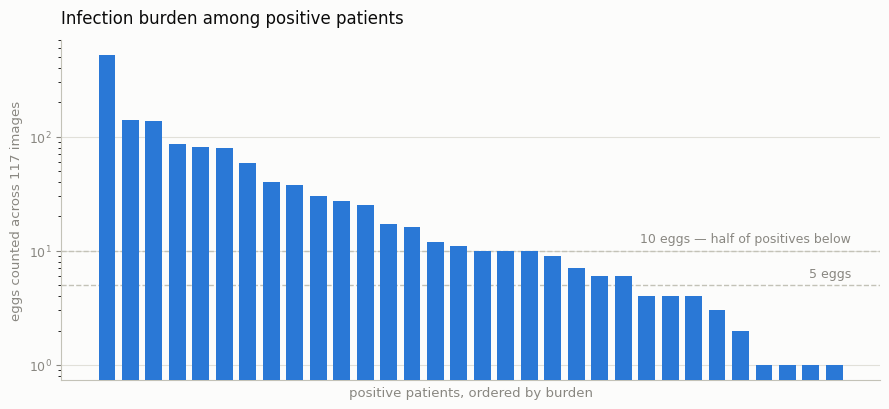

In [13]:
import matplotlib.pyplot as plt

INK, MUTED, GRID, AXIS = "#0b0b0b", "#898781", "#e1e0d9", "#c3c2b7"
SURFACE, BLUE = "#fcfcfb", "#2a78d6"
plt.rcParams["font.family"] = "DejaVu Sans"

counts = np.sort(pos.values)[::-1]

fig, ax = plt.subplots(figsize=(9, 4.2), facecolor=SURFACE)
ax.set_facecolor(SURFACE)

ax.bar(range(len(counts)), counts, color=BLUE, width=0.72, zorder=3)
ax.set_yscale("log")

for y, lab in ((10, "10 eggs — half of positives below"), (5, "5 eggs")):
    ax.axhline(y, color=AXIS, lw=1, ls="--", zorder=2)
    ax.text(len(counts) - 0.3, y * 1.12, lab, ha="right", va="bottom",
            fontsize=9, color=MUTED)

ax.set_xlabel("positive patients, ordered by burden", fontsize=9.5, color=MUTED)
ax.set_ylabel("eggs counted across 117 images", fontsize=9.5, color=MUTED)
ax.set_title("Infection burden among positive patients",
             fontsize=12, color=INK, loc="left", pad=12)

ax.grid(axis="y", color=GRID, lw=0.8, zorder=0)
ax.set_axisbelow(True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
for s in ("left", "bottom"):
    ax.spines[s].set_color(AXIS)
ax.tick_params(colors=MUTED, labelsize=9)
ax.set_xticks([])

plt.tight_layout()
plt.savefig("/kaggle/working/fig_burden.png", dpi=200, facecolor=SURFACE)
plt.show()

## 3 · From images to numbers

A classifier cannot work on raw pixels at this sample size. Each image is
passed through a ResNet50 trained on ImageNet and frozen — its weights are
never updated here. What comes out is a 4,096-number description of the
image in terms of shape, texture and contrast, which is a representation
small enough for 65 patients to support.

Images are read directly from the archive and transformed in memory, so
nothing is written to disk between the zip and the GPU.

In [14]:
import torchvision
from torch import nn
from torchvision import transforms
from PIL import Image

DEV = "cuda"
TF = transforms.Compose([
    transforms.Resize((384, 512)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

net      = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2)
backbone = nn.Sequential(*list(net.children())[:-2]).to(DEV).eval()

@torch.no_grad()
def embed(batch):
    with torch.autocast("cuda", dtype=torch.float16):
        fm = backbone(batch)
    fm = fm.float()
    return torch.cat([fm.mean(dim=(2, 3)), fm.amax(dim=(2, 3))], dim=1)

SAMPLES = sorted(labels.sample_id)
BATCH   = 48

feats, meta = [], []
buf = []

for sid in tqdm(SAMPLES, desc="patients"):
    paths = sorted(n for n in IMGS if f"/{sid}/" in n)
    assert len(paths) == 117, f"{sid} has {len(paths)} images"
    for p in paths:
        img = Image.open(io.BytesIO(zf.read(p))).convert("RGB")
        buf.append(TF(img))
        meta.append((sid, pathlib.PurePosixPath(p).name))
        if len(buf) == BATCH:
            feats.append(embed(torch.stack(buf).to(DEV)).cpu().numpy())
            buf = []

if buf:
    feats.append(embed(torch.stack(buf).to(DEV)).cpu().numpy())

X = np.concatenate(feats).astype(np.float32)
print("\nfeature matrix:", X.shape)
assert X.shape == (7605, 4096), X.shape

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:02<00:00, 47.4MB/s]


patients:   0%|          | 0/65 [00:00<?, ?it/s]


feature matrix: (7605, 4096)


### Save the features

The feature matrix is written to disk before anything else runs. Extracting
it cost nine minutes of GPU time on top of a 42-minute download; saving it
now means neither has to be repeated if the session ends.

In [15]:
sids = np.array([m[0] for m in meta])
fns  = np.array([m[1] for m in meta])

np.savez_compressed(
    "/kaggle/working/features_frames.npz",
    X=X, sample_id=sids, filename=fns,
    labels_sample_id=labels.sample_id.values,
    labels_diagnosis=labels.diagnosis.values,
    labels_egg_count=labels.egg_count.values,
)

import os
print(f"saved · {os.path.getsize('/kaggle/working/features_frames.npz')/1e6:.0f} MB")

_, _, free = shutil.disk_usage("/kaggle/working")
print(f"disk free · {free/1e9:.1f} GB")

saved · 51 MB
disk free · 8.4 GB


## 4 · A finer representation

An egg occupies perhaps 1% of a full frame. Cut that frame into twelve tiles
and the same egg occupies around 12% of whichever tile it lands in — the egg
has not changed, but its share of the thing being scored has.

Each image is resized to 1024 × 768 and divided into a 3 × 4 grid of
256 × 256 tiles, giving 1,404 instances per patient instead of 117. Whether
this helps is the second question this notebook asks, and the answer is not
assumed: both representations are carried forward and compared.

In [16]:
TF_FULL = transforms.Compose([
    transforms.Resize((768, 1024)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

ROWS, COLS, PX = 3, 4, 256
TILES_PER_IMG = ROWS * COLS

def to_tiles(t):
    return [t[:, r*PX:(r+1)*PX, c*PX:(c+1)*PX]
            for r in range(ROWS) for c in range(COLS)]

BATCH_T = 96
feats_t, meta_t, buf = [], [], []

for sid in tqdm(SAMPLES, desc="patients (tiled)"):
    paths = sorted(n for n in IMGS if f"/{sid}/" in n)
    for p in paths:
        img = Image.open(io.BytesIO(zf.read(p))).convert("RGB")
        full = TF_FULL(img)
        fname = pathlib.PurePosixPath(p).name
        for k, tile in enumerate(to_tiles(full)):
            buf.append(tile)
            meta_t.append((sid, fname, k))
            if len(buf) == BATCH_T:
                feats_t.append(embed(torch.stack(buf).to(DEV)).cpu().numpy())
                buf = []

if buf:
    feats_t.append(embed(torch.stack(buf).to(DEV)).cpu().numpy())

Xt = np.concatenate(feats_t).astype(np.float32)
print("\ntiled feature matrix:", Xt.shape)
assert Xt.shape == (65 * 1404, 4096), Xt.shape

patients (tiled):   0%|          | 0/65 [00:00<?, ?it/s]


tiled feature matrix: (91260, 4096)


### Save the tiled features

Uncompressed here rather than compressed: float32 features barely compress,
and the write is many times faster. 1.4 GB on disk, regenerable in thirteen
minutes if ever lost.

In [17]:
sids_t = np.array([m[0] for m in meta_t])
fns_t  = np.array([m[1] for m in meta_t])
pos_t  = np.array([m[2] for m in meta_t], dtype=np.int16)

np.savez("/kaggle/working/features_tiles.npz",
         X=Xt, sample_id=sids_t, filename=fns_t, tile=pos_t)

print(f"saved · {os.path.getsize('/kaggle/working/features_tiles.npz')/1e9:.2f} GB")
_, _, free = shutil.disk_usage("/kaggle/working")
print(f"disk free · {free/1e9:.1f} GB")

saved · 1.50 GB
disk free · 6.9 GB


### What a frame actually looks like

Four frames from the most heavily infected patient in the set, and four from
a negative one. Even at 516 eggs — the highest burden here, spread across
117 images — most individual frames hold nothing distinguishable. That is
the reason a per-image rule struggles: the evidence is not in the typical
frame, it is in a handful of them.

positive: DT29 (516 eggs)   negative: DT02


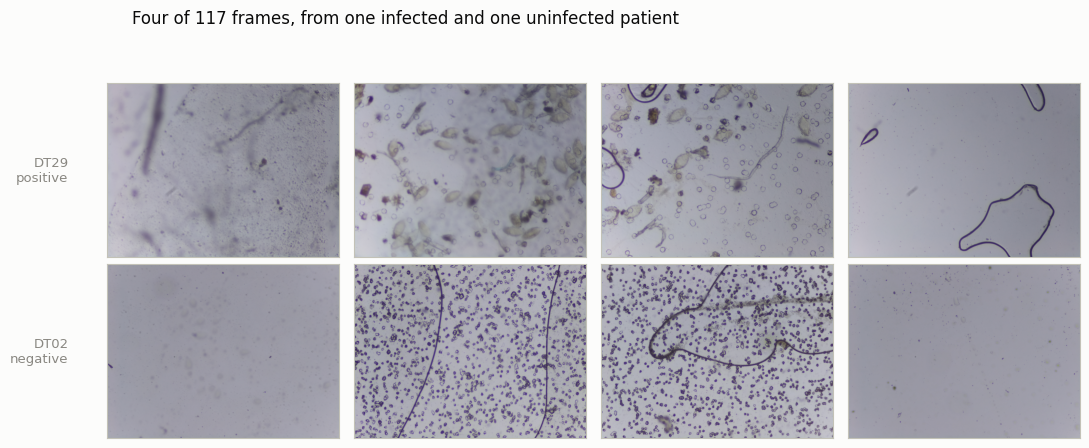

In [18]:
top_pos = labels.loc[labels.egg_count.idxmax(), "sample_id"]
a_neg   = labels.loc[labels.diagnosis == 0, "sample_id"].iloc[0]
print(f"positive: {top_pos} ({labels.egg_count.max()} eggs)   negative: {a_neg}")

def four_frames(sid):
    paths = sorted(n for n in IMGS if f"/{sid}/" in n)
    picks = [paths[i] for i in (0, 39, 78, 116)]
    return [Image.open(io.BytesIO(zf.read(p))).convert("RGB") for p in picks]

rows = [(top_pos, four_frames(top_pos)), (a_neg, four_frames(a_neg))]

fig, axes = plt.subplots(2, 4, figsize=(11, 4.6), facecolor=SURFACE)
for r, (sid, imgs) in enumerate(rows):
    for c, im in enumerate(imgs):
        ax = axes[r, c]
        ax.imshow(im)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_color(AXIS); s.set_linewidth(0.8)
        if c == 0:
            tag = "positive" if r == 0 else "negative"
            ax.set_ylabel(f"{sid}\n{tag}", fontsize=9.5, color=MUTED, rotation=0,
                          ha="right", va="center", labelpad=28)

fig.suptitle("Four of 117 frames, from one infected and one uninfected patient",
             fontsize=12, color=INK, x=0.125, ha="left", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig("/kaggle/working/fig_frames.png", dpi=200, facecolor=SURFACE)
plt.show()

## 5 · Bags

One patient is a bag of instances. In the whole-frame representation a bag
holds 117 instances; tiled, it holds 1,404. The label belongs to the bag,
not to any instance inside it — nothing in this dataset says which frame or
which tile contains an egg. That is what makes this weakly supervised, and
it is the reason aggregation is a modelling problem rather than a formality.

In [19]:
assert list(SAMPLES) == list(labels.sample_id), "label order does not match bag order"

BAGS   = X.reshape(65, 117, 4096)
BAGS_T = Xt.reshape(65, 1404, 4096)
y      = labels.diagnosis.values.astype(int)
eggs   = labels.egg_count.values.astype(int)

assert (sids.reshape(65, 117)[:, 0] == np.array(SAMPLES)).all(), "frame bags misaligned"
assert (sids_t.reshape(65, 1404)[:, 0] == np.array(SAMPLES)).all(), "tiled bags misaligned"

print(f"frame bags  {BAGS.shape}")
print(f"tiled bags  {BAGS_T.shape}")
print(f"labels      {y.shape}   {y.sum()} positive, {(1-y).sum()} negative")

frame bags  (65, 117, 4096)
tiled bags  (65, 1404, 4096)
labels      (65,)   32 positive, 33 negative


## 6 · Three ways to collapse a bag

A bag holds 117 or 1,404 instances; a decision needs one number. Three
strategies are compared.

**Mean-pooling** averages the instances into a single vector, then a linear
classifier scores that vector. **Max-pooling** takes the strongest value in
each of the 4,096 dimensions instead. Neither has any learned parameter in
the pooling step — the only thing that trains is the classifier afterwards.

**Gated attention MIL** learns a weight for every instance and takes a
weighted average, so the pooling itself is trained. In principle it should
beat both, because it can learn to ignore empty instances. Whether it does
at 65 patients is the first question.

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

SEED = 0
torch.manual_seed(SEED); np.random.seed(SEED)

class GatedAttentionMIL(nn.Module):
    """Ilse et al. (2018). Returns attention weights alongside the logit —
    they are what tells a reviewer which instances to open."""
    def __init__(self, d_in=4096, d=256, d_att=128, p_drop=0.25):
        super().__init__()
        self.feat  = nn.Sequential(nn.LayerNorm(d_in), nn.Linear(d_in, d),
                                   nn.ReLU(), nn.Dropout(p_drop))
        self.att_V = nn.Sequential(nn.Linear(d, d_att), nn.Tanh())
        self.att_U = nn.Sequential(nn.Linear(d, d_att), nn.Sigmoid())
        self.att_w = nn.Linear(d_att, 1)
        self.head  = nn.Linear(d, 1)

    def forward(self, bags):
        h = self.feat(bags)
        a = self.att_w(self.att_V(h) * self.att_U(h))
        a = torch.softmax(a, dim=1)
        z = (a * h).sum(dim=1)
        return self.head(z).squeeze(-1), a.squeeze(-1)

def fit_mil(Xtr, ytr, Xte, epochs=60, lr=3e-4, wd=1e-4, seed=0):
    torch.manual_seed(seed)
    m   = GatedAttentionMIL(d_in=Xtr.shape[-1]).to(DEV)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=wd)
    lossf = nn.BCEWithLogitsLoss()
    xb = torch.tensor(Xtr, device=DEV)
    yb = torch.tensor(ytr, dtype=torch.float32, device=DEV)
    m.train()
    for _ in range(epochs):
        opt.zero_grad()
        logit, _ = m(xb)
        lossf(logit, yb).backward()
        opt.step()
    m.eval()
    with torch.no_grad():
        logit, att = m(torch.tensor(Xte, device=DEV))
        return torch.sigmoid(logit).cpu().numpy(), att.cpu().numpy()

def fit_pooled(Xtr, ytr, Xte, how):
    pool = (lambda B: B.mean(axis=1)) if how == "mean" else (lambda B: B.max(axis=1))
    clf  = make_pipeline(StandardScaler(),
                         LogisticRegression(max_iter=2000, C=1.0))
    clf.fit(pool(Xtr), ytr)
    return clf.predict_proba(pool(Xte))[:, 1]
print("defined: GatedAttentionMIL, fit_mil, fit_pooled")

defined: GatedAttentionMIL, fit_mil, fit_pooled


## 7 · Validation

Repeated stratified five-fold cross-validation, five repeats — 25 fits per
method. Repeating matters at this size: a single five-fold run on 65 patients
can swing by a lot depending on which patients land where, and reporting one
such run would overstate what is known.

**Splits are over patients, never over images.** Every instance belonging to
a patient moves together. Splitting on images would place frames from the
same sample in training and testing at once; the model would learn to
recognise the patient rather than the disease, and the scores would be
inflated and meaningless. This is the principal way a design like this leaks.

In [24]:
from sklearn.model_selection import RepeatedStratifiedKFold

N_SPLITS, N_REPEATS = 5, 5
rskf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS,
                               random_state=SEED)

def run_cv(B, tag):
    n_inst = B.shape[1]
    oof = {m: np.zeros((N_REPEATS, 65)) for m in ("mil", "mean", "max")}
    att = np.zeros((N_REPEATS, 65, n_inst), dtype=np.float32)

    for i, (tr, te) in enumerate(tqdm(rskf.split(np.zeros(65), y),
                                      total=N_SPLITS * N_REPEATS, desc=tag)):
        r = i // N_SPLITS
        p_mil, a = fit_mil(B[tr], y[tr], B[te], seed=SEED + i)
        oof["mil"][r, te]  = p_mil
        att[r, te]         = a
        oof["mean"][r, te] = fit_pooled(B[tr], y[tr], B[te], "mean")
        oof["max"][r, te]  = fit_pooled(B[tr], y[tr], B[te], "max")
    return oof, att

oof_f, att_f = run_cv(BAGS,   "whole frame")
oof_t, att_t = run_cv(BAGS_T, "tiled")

np.savez("/kaggle/working/oof.npz",
         **{f"frame_{k}": v for k, v in oof_f.items()},
         **{f"tiled_{k}": v for k, v in oof_t.items()},
         att_frame=att_f, att_tiled=att_t, y=y, eggs=eggs,
         sample_id=np.array(SAMPLES))
print("\nsaved oof.npz")

whole frame:   0%|          | 0/25 [00:00<?, ?it/s]

tiled:   0%|          | 0/25 [00:00<?, ?it/s]


saved oof.npz


## 8 · Results

Five metrics, each averaged over the five repeats with its spread.

**AUROC** measures ranking — given one infected and one healthy patient at
random, how often the infected one scores higher. It is independent of where
a threshold is placed.

**Sensitivity and specificity at 0.5** are what you get from the obvious
threshold.

**Specificity at 90% sensitivity** is the screening-relevant figure: hold
sensitivity at a level a programme would accept, then ask how many healthy
patients are correctly cleared.

**Sensitivity among low-burden positives** is performance on the half of
infected patients carrying ten eggs or fewer — the hardest cases, and the
ones worth catching earliest.

In [25]:
from sklearn.metrics import roc_auc_score, roc_curve

LOW = (eggs > 0) & (eggs <= 10)
print(f"low-burden positives: {LOW.sum()} of {y.sum()}\n")

def spec_at_sens(yt, p, target=0.90):
    fpr, tpr, _ = roc_curve(yt, p)
    ok = tpr >= target
    return (1 - fpr[ok]).max() if ok.any() else 0.0

def metrics(oof, name):
    rows = []
    for r in range(N_REPEATS):
        p = oof[r]
        hit = p >= 0.5
        rows.append(dict(
            auroc      = roc_auc_score(y, p),
            sens       = hit[y == 1].mean(),
            spec       = (~hit[y == 0]).mean(),
            spec_at_90 = spec_at_sens(y, p),
            sens_low   = hit[LOW].mean(),
        ))
    d = pd.DataFrame(rows)
    return pd.Series({
        "AUROC":        f"{d.auroc.mean():.3f} ± {d.auroc.std():.3f}",
        "Sens@0.5":     f"{d.sens.mean():.3f}",
        "Spec@0.5":     f"{d.spec.mean():.3f}",
        "Spec@90%Sens": f"{d.spec_at_90.mean():.3f}",
        "Sens ≤10 eggs":f"{d.sens_low.mean():.3f}",
    }, name=name)

NAMES = {"mil": "Attention MIL", "mean": "Mean-pooling", "max": "Max-pooling"}

for title, oof in (("WHOLE FRAME — 117 instances", oof_f),
                   ("TILED — 1,404 instances",     oof_t)):
    print(title)
    print(pd.DataFrame([metrics(oof[m], NAMES[m]) for m in NAMES]).to_string())
    print()

low-burden positives: 16 of 32

WHOLE FRAME — 117 instances
                       AUROC Sens@0.5 Spec@0.5 Spec@90%Sens Sens ≤10 eggs
Attention MIL  0.731 ± 0.042    0.681    0.667        0.388         0.662
Mean-pooling   0.707 ± 0.025    0.681    0.630        0.339         0.600
Max-pooling    0.723 ± 0.017    0.713    0.703        0.333         0.637

TILED — 1,404 instances
                       AUROC Sens@0.5 Spec@0.5 Spec@90%Sens Sens ≤10 eggs
Attention MIL  0.641 ± 0.033    0.613    0.606        0.273         0.550
Mean-pooling   0.672 ± 0.027    0.662    0.642        0.212         0.575
Max-pooling    0.762 ± 0.019    0.725    0.667        0.455         0.675



## 9 · Why attention lost

Two hypotheses, and they predict opposite measurements.

**It gave up.** If attention spread its weight evenly it would have
degenerated into mean-pooling, and its effective number of attended
instances would sit close to the bag size.

**It focused on the wrong things.** Then weight would be concentrated on
few instances — but on *different* instances each time it is trained, since
nothing in the data tells it which instances matter.

The first is underfitting, the second is overfitting, and they call for
different responses. Three measurements separate them: how concentrated the
weights are, how much mass the top instances carry, and whether repeated
fits agree on which instances deserve it.

In [26]:
def attention_report(att, tag):
    R, P, N = att.shape
    a = np.clip(att, 1e-12, None)

    ent  = -(a * np.log(a)).sum(axis=2)        # (R, P)
    eff  = np.exp(ent)                          # effective instances attended
    top10 = np.sort(a, axis=2)[:, :, -10:].sum(axis=2)

    # do repeated fits agree on which instances matter?
    idx = np.argsort(att, axis=2)[:, :, -10:]
    jac = []
    for p in range(P):
        for i in range(R):
            for j in range(i + 1, R):
                s1, s2 = set(idx[i, p]), set(idx[j, p])
                jac.append(len(s1 & s2) / len(s1 | s2))
    jac = np.array(jac)

    print(f"{tag}  —  bag size {N}")
    print(f"  effective instances attended   {eff.mean():7.1f}  ({eff.mean()/N:.1%} of bag)")
    print(f"  mass on top 10 instances       {top10.mean():7.3f}")
    print(f"  uniform weight per instance    {1/N:7.5f}")
    print(f"  mean top-10 weight             {top10.mean()/10:7.5f}"
          f"   ({(top10.mean()/10)/(1/N):.0f}× uniform)")
    print(f"  top-10 agreement across repeats {jac.mean():7.3f}  (1.0 = identical)")
    print()

attention_report(att_f, "WHOLE FRAME")
attention_report(att_t, "TILED")

WHOLE FRAME  —  bag size 117
  effective instances attended      18.5  (15.8% of bag)
  mass on top 10 instances         0.795
  uniform weight per instance    0.00855
  mean top-10 weight             0.07950   (9× uniform)
  top-10 agreement across repeats   0.369  (1.0 = identical)

TILED  —  bag size 1404
  effective instances attended     130.6  (9.3% of bag)
  mass on top 10 instances         0.540
  uniform weight per instance    0.00071
  mean top-10 weight             0.05395   (76× uniform)
  top-10 agreement across repeats   0.163  (1.0 = identical)



Both measurements point the same way. Attention is highly concentrated —
80% of a whole-frame decision rests on 10 of 117 instances, and tiled, the
top ten carry 76× uniform weight. It has not degenerated into averaging.

But repeated fits do not agree on *which* instances deserve that weight.
Two models share roughly three of their top ten tiles, against an expected
0.004 Jaccard by chance — above random, far below what locating a real egg
would produce.

Agreement falls from 0.369 to 0.163 moving to the finer representation, and
AUROC falls 0.731 to 0.641 alongside it. More instances gives more room to
disagree, and performance follows.

The failure is not a lack of selectivity. It is confident selectivity
pointed at different things each time — overfitting, with 52 training bags,
roughly a million parameters, and no instance-level supervision to anchor
it.

## 10 · How much of the bag should a decision draw on?

The first two questions compared ways of pooling. This one asks about the
rule itself.

A linear probe scores every tile independently, trained with the patient's
label propagated to all 1,404 of their tiles — crude supervision, but it is
all the data provides. Each patient's tile scores are then sorted and the
top k averaged into one probability.

k = 1 is exactly the any-detection rule the Schistoscope uses: the single
strongest region decides the patient. k = 1404 is plain averaging. Sweeping
between them asks how much evidence a diagnosis should rest on.

In [27]:
K_GRID = [1, 2, 5, 10, 25, 50, 100, 250, 500, 1000, 1404]

def fit_instance_scorer(Btr, ytr, Bte, epochs=30, bs=16384, lr=1e-3, seed=0):
    torch.manual_seed(seed)
    n_tr, n_inst, d = Btr.shape
    Xi = torch.tensor(Btr.reshape(-1, d))
    yi = torch.tensor(np.repeat(ytr, n_inst), dtype=torch.float32)

    model = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 1)).to(DEV)
    opt   = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    lossf = nn.BCEWithLogitsLoss()

    model.train()
    for _ in range(epochs):
        perm = torch.randperm(Xi.shape[0])
        for s in range(0, len(perm), bs):
            idx = perm[s:s+bs]
            xb = Xi[idx].to(DEV); yb = yi[idx].to(DEV)
            opt.zero_grad()
            lossf(model(xb).squeeze(-1), yb).backward()
            opt.step()

    model.eval()
    out = []
    with torch.no_grad():
        for b in Bte:
            s = torch.sigmoid(model(torch.tensor(b).to(DEV)).squeeze(-1))
            out.append(s.cpu().numpy())
    return np.stack(out)                      # (n_test, n_inst)

sweep = {k: np.zeros((N_REPEATS, 65)) for k in K_GRID}

for i, (tr, te) in enumerate(tqdm(rskf.split(np.zeros(65), y),
                                  total=N_SPLITS * N_REPEATS, desc="top-k sweep")):
    r = i // N_SPLITS
    S = fit_instance_scorer(BAGS_T[tr], y[tr], BAGS_T[te], seed=SEED + i)
    S = np.sort(S, axis=1)[:, ::-1]           # descending per patient
    for k in K_GRID:
        sweep[k][r, te] = S[:, :k].mean(axis=1)

np.savez("/kaggle/working/sweep.npz",
         **{f"k{k}": v for k, v in sweep.items()}, k_grid=np.array(K_GRID))
print("\nsaved sweep.npz")

top-k sweep:   0%|          | 0/25 [00:00<?, ?it/s]


saved sweep.npz


Thresholding a top-k mean at 0.5 is not meaningful — averaging the top
instance scores shifts the whole distribution, differently for each k. So
this table reports the two figures that do not depend on an arbitrary cut:
AUROC, which measures ranking, and specificity at a fixed 90% sensitivity,
which is the operating point a screening programme would actually set.

Spread across the five repeats is reported for both. At 65 patients, how
much a number moves is as informative as the number.

In [28]:
rows = []
for k in K_GRID:
    au, sp, sl = [], [], []
    for r in range(N_REPEATS):
        p = sweep[k][r]
        au.append(roc_auc_score(y, p))
        sp.append(spec_at_sens(y, p))
        thr = np.quantile(p, 1 - y.mean())        # match predicted positive rate
        sl.append((p[LOW] >= thr).mean())
    rows.append(dict(
        k            = k,
        AUROC        = f"{np.mean(au):.3f} ± {np.std(au):.3f}",
        Spec_at_90   = f"{np.mean(sp):.3f} ± {np.std(sp):.3f}",
        Sens_low     = f"{np.mean(sl):.3f}",
    ))

tbl = pd.DataFrame(rows).set_index("k")
print(tbl.to_string())

best = max(K_GRID, key=lambda k: np.mean([spec_at_sens(y, sweep[k][r])
                                          for r in range(N_REPEATS)]))
k1 = np.mean([spec_at_sens(y, sweep[1][r]) for r in range(N_REPEATS)])
kb = np.mean([spec_at_sens(y, sweep[best][r]) for r in range(N_REPEATS)])
print(f"\nbest k = {best}   Spec@90%Sens {kb:.3f}   vs k=1 {k1:.3f}"
      f"   ({kb-k1:+.3f})")

              AUROC     Spec_at_90 Sens_low
k                                          
1     0.743 ± 0.028  0.400 ± 0.052    0.713
2     0.742 ± 0.023  0.394 ± 0.038    0.713
5     0.742 ± 0.017  0.376 ± 0.036    0.725
10    0.737 ± 0.018  0.376 ± 0.031    0.725
25    0.735 ± 0.023  0.370 ± 0.059    0.725
50    0.728 ± 0.025  0.412 ± 0.059    0.713
100   0.725 ± 0.025  0.442 ± 0.083    0.725
250   0.722 ± 0.025  0.467 ± 0.073    0.725
500   0.716 ± 0.024  0.485 ± 0.054    0.713
1000  0.708 ± 0.021  0.388 ± 0.075    0.700
1404  0.705 ± 0.021  0.358 ± 0.091    0.700

best k = 500   Spec@90%Sens 0.485   vs k=1 0.400   (+0.085)


### Figure — aggregation breadth

Two panels, same horizontal axis. On the left, ranking quality falls as the
decision draws on more of the bag. On the right, specificity at the clinical
operating point rises to a peak around k = 500 and then collapses.

They disagree, and that disagreement is the point: a rule can rank patients
well and still make poor decisions at the threshold a programme actually
uses. Shaded bands are ±1 standard deviation across the five repeats.

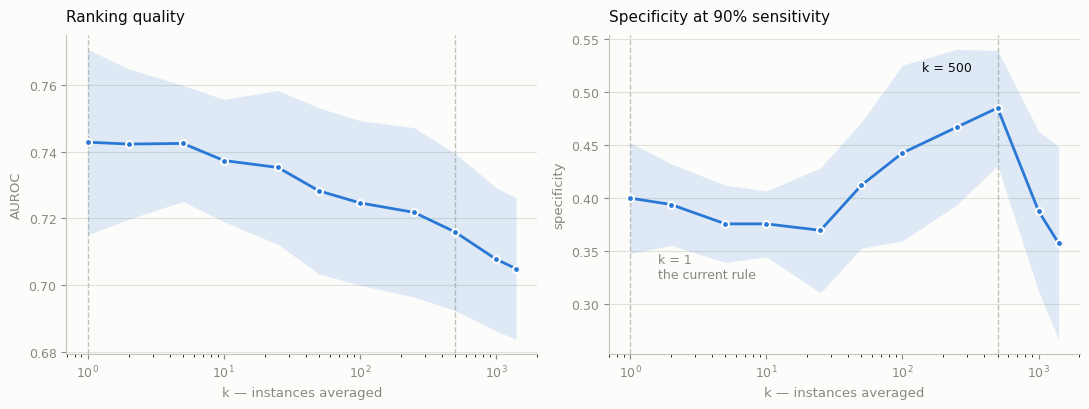

In [29]:
au_m, au_s, sp_m, sp_s = [], [], [], []
for k in K_GRID:
    a = [roc_auc_score(y, sweep[k][r]) for r in range(N_REPEATS)]
    s = [spec_at_sens(y, sweep[k][r])  for r in range(N_REPEATS)]
    au_m.append(np.mean(a)); au_s.append(np.std(a))
    sp_m.append(np.mean(s)); sp_s.append(np.std(s))

au_m, au_s = np.array(au_m), np.array(au_s)
sp_m, sp_s = np.array(sp_m), np.array(sp_s)
ks = np.array(K_GRID)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), facecolor=SURFACE, sharex=True)

panels = [
    (axes[0], au_m, au_s, "AUROC", "Ranking quality"),
    (axes[1], sp_m, sp_s, "specificity", "Specificity at 90% sensitivity"),
]

for ax, m, s, ylab, title in panels:
    ax.set_facecolor(SURFACE)
    ax.fill_between(ks, m - s, m + s, color=BLUE, alpha=0.14, lw=0, zorder=2)
    ax.plot(ks, m, color=BLUE, lw=2, zorder=3)
    ax.plot(ks, m, "o", color=BLUE, ms=5, mec=SURFACE, mew=1.5, zorder=4)
    ax.set_xscale("log")
    ax.set_xlabel("k — instances averaged", fontsize=9.5, color=MUTED)
    ax.set_ylabel(ylab, fontsize=9.5, color=MUTED)
    ax.set_title(title, fontsize=11, color=INK, loc="left", pad=10)
    ax.grid(axis="y", color=GRID, lw=0.8, zorder=0)
    ax.set_axisbelow(True)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    for sp in ("left", "bottom"): ax.spines[sp].set_color(AXIS)
    ax.tick_params(colors=MUTED, labelsize=9)

for ax in axes:
    ax.axvline(1, color=AXIS, ls="--", lw=1, zorder=1)
    ax.axvline(500, color=AXIS, ls="--", lw=1, zorder=1)

axes[1].annotate("k = 1\nthe current rule", xy=(1, sp_m[0]),
                 xytext=(1.6, sp_m[0] - 0.075), fontsize=9, color=MUTED)
axes[1].annotate("k = 500", xy=(500, sp_m[K_GRID.index(500)]),
                 xytext=(140, sp_m[K_GRID.index(500)] + 0.035),
                 fontsize=9, color=INK)

plt.tight_layout()
plt.savefig("/kaggle/working/fig_topk.png", dpi=200, facecolor=SURFACE)
plt.show()

## 11 · Does deferring help?

The system declines to decide on cases near its threshold. The claim is that
those are the cases it would most likely get wrong — so handing them to a
person should buy accuracy on everything left.

That is an assumption until it is measured, and there is an obvious null:
deferring on *randomly chosen* patients also removes cases, and some of them
would also have been wrong. If confidence-based deferral is no better than
random at the same workload, the mechanism is decoration.

Three things are computed, using the k = 500 configuration:

**A risk–coverage curve.** Patients are ordered by how far their probability
sits from the decision threshold. Coverage is the fraction decided
automatically; risk is the error rate among those. Sweeping coverage from
100% down shows what each referral buys.

**AURC** — the area under that curve. One number: lower is better.

**A random-deferral control.** The same coverage levels, patients chosen at
random. The gap between the two curves is the entire value of the mechanism.

In [30]:
P = sweep[500]                                    # (N_REPEATS, 65)
prev = y.mean()
COV = np.linspace(1.0, 0.2, 33)                   # 100% down to 20%
RNG = np.random.default_rng(SEED)
N_DRAWS = 200

def risk_coverage(p, yt):
    thr  = np.quantile(p, 1 - prev)
    pred = (p >= thr).astype(int)
    err  = (pred != yt).astype(float)
    conf = np.abs(p - thr)
    order = np.argsort(-conf)                     # most confident first

    risks, rand = [], []
    for c in COV:
        n = max(1, int(round(c * len(yt))))
        risks.append(err[order[:n]].mean())
        draws = [err[RNG.choice(len(yt), n, replace=False)].mean()
                 for _ in range(N_DRAWS)]
        rand.append(np.mean(draws))
    return np.array(risks), np.array(rand)

rc  = np.stack([risk_coverage(P[r], y)[0] for r in range(N_REPEATS)])
rnd = np.stack([risk_coverage(P[r], y)[1] for r in range(N_REPEATS)])

aurc_c = np.trapz(rc.mean(axis=0)[::-1],  COV[::-1]) / (COV[0] - COV[-1])
aurc_r = np.trapz(rnd.mean(axis=0)[::-1], COV[::-1]) / (COV[0] - COV[-1])

print(f"error at full coverage        {rc.mean(axis=0)[0]:.3f}")
print(f"AURC, confidence-based        {aurc_c:.4f}")
print(f"AURC, random deferral         {aurc_r:.4f}")
print(f"improvement                   {aurc_r - aurc_c:+.4f}"
      f"   ({(aurc_r-aurc_c)/aurc_r:+.1%})\n")

for c in (1.0, 0.9, 0.8, 0.7, 0.6, 0.5):
    i = np.argmin(np.abs(COV - c))
    print(f"coverage {c:.0%}   confidence {rc.mean(axis=0)[i]:.3f}"
          f"   random {rnd.mean(axis=0)[i]:.3f}"
          f"   Δ {rnd.mean(axis=0)[i] - rc.mean(axis=0)[i]:+.3f}")

error at full coverage        0.283
AURC, confidence-based        0.2755
AURC, random deferral         0.2829
improvement                   +0.0074   (+2.6%)

coverage 100%   confidence 0.283   random 0.283   Δ -0.000
coverage 90%   confidence 0.279   random 0.283   Δ +0.003
coverage 80%   confidence 0.281   random 0.282   Δ +0.002
coverage 70%   confidence 0.296   random 0.284   Δ -0.011
coverage 60%   confidence 0.303   random 0.283   Δ -0.019
coverage 50%   confidence 0.269   random 0.283   Δ +0.014


/tmp/ipykernel_48/1116786703.py:26: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  aurc_c = np.trapz(rc.mean(axis=0)[::-1],  COV[::-1]) / (COV[0] - COV[-1])
/tmp/ipykernel_48/1116786703.py:27: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  aurc_r = np.trapz(rnd.mean(axis=0)[::-1], COV[::-1]) / (COV[0] - COV[-1])


### Why — is the signal absent or mangled?

Either the probabilities carry information that the confidence measure fails
to read — averaging 500 sigmoid outputs compresses the range, and distance
from a threshold means little if every patient sits within a sliver of it —
or they carry no information about correctness at all.

Below: the spread of the probabilities, and the error rate across confidence
quintiles. If confidence is informative, error should fall steadily from the
least confident group to the most.

In [31]:
p = P.mean(axis=0)                     # average across repeats
thr = np.quantile(p, 1 - prev)
pred = (p >= thr).astype(int)
wrong = (pred != y)

print(f"probability range   {p.min():.4f} – {p.max():.4f}   (spread {p.std():.4f})")
print(f"threshold           {thr:.4f}")
print(f"errors              {wrong.sum()} of 65\n")

conf = np.abs(p - thr)
q = pd.qcut(conf, 5, labels=["least confident", "2", "3", "4", "most confident"])
print(pd.DataFrame({"confidence": q, "wrong": wrong})
      .groupby("confidence", observed=True)["wrong"]
      .agg(["mean", "sum", "count"])
      .rename(columns={"mean": "error rate", "sum": "errors", "count": "n"})
      .to_string())

probability range   0.2933 – 0.8992   (spread 0.1688)
threshold           0.7311
errors              18 of 65

                 error rate  errors   n
confidence                             
least confident    0.230769       3  13
2                  0.230769       3  13
3                  0.384615       5  13
4                  0.384615       5  13
most confident     0.153846       2  13


The probabilities are not compressed: they span 0.29 to 0.90. But error does
not fall with confidence — 23%, 23%, 38%, 38%, 15% across quintiles, rising
through the middle. The model discriminates between patients without knowing
when it is wrong.

The signal is absent rather than mangled, so no alternative confidence
measure recovers it. With 13 patients per quintile this test could only have
detected a strong relationship; the honest claim is that none is detectable
at n = 65.

In [32]:
print("files in /kaggle/working:\n")
for f in sorted(pathlib.Path("/kaggle/working").iterdir()):
    if f.is_file():
        print(f"  {f.name:34s} {f.stat().st_size/1e6:8.1f} MB")

files in /kaggle/working:

  diagnosis_test_dataset.zip          12519.0 MB
  features_frames.npz                    50.6 MB
  features_tiles.npz                   1502.0 MB
  fig_burden.png                          0.1 MB
  fig_frames.png                          1.8 MB
  fig_topk.png                            0.1 MB
  oof.npz                                 2.0 MB
  sweep.npz                               0.0 MB


In [33]:
from IPython.display import FileLink, display

for f in ["features_frames.npz", "oof.npz", "sweep.npz",
          "fig_burden.png", "fig_frames.png", "fig_topk.png"]:
    display(FileLink(f))

/kaggle/working/features_frames.npz

/kaggle/working/oof.npz

/kaggle/working/sweep.npz

/kaggle/working/fig_burden.png

/kaggle/working/fig_frames.png

/kaggle/working/fig_topk.png

In [34]:
import tarfile

TAR = "/kaggle/working/frames_1024.tar"

with tarfile.open(TAR, "w") as tar:
    for sid in tqdm(SAMPLES, desc="packing"):
        for p in sorted(n for n in IMGS if f"/{sid}/" in n):
            img = Image.open(io.BytesIO(zf.read(p))).convert("RGB")
            img = img.resize((1024, 768), Image.LANCZOS)
            buf = io.BytesIO()
            img.save(buf, "JPEG", quality=88)
            data = buf.getvalue()
            info = tarfile.TarInfo(f"{sid}/{pathlib.PurePosixPath(p).name}")
            info.size = len(data)
            tar.addfile(info, io.BytesIO(data))

print(f"\n{TAR}  ·  {os.path.getsize(TAR)/1e9:.2f} GB")

packing:   0%|          | 0/65 [00:00<?, ?it/s]


/kaggle/working/frames_1024.tar  ·  0.92 GB


### Save the prepared frames

The 7,605 images are written to a single tar at 1024 × 768 — the resolution
the tiling used, so tiles can be cut straight from it later.

One file rather than thousands. Kaggle charges a round trip per file when
attaching a dataset, so loose images take hours to mount while a single
archive of the same size takes minutes. The source zip is then removed: the
tar holds everything downstream notebooks need, and the original remains on
Zenodo.

In [35]:
zf.close()
os.remove(ZIP_PATH)

print("files to be saved:\n")
total = 0
for f in sorted(pathlib.Path("/kaggle/working").iterdir()):
    if f.is_file():
        total += f.stat().st_size
        print(f"  {f.name:30s} {f.stat().st_size/1e6:8.1f} MB")
print(f"\n  total {total/1e9:.2f} GB")

files to be saved:

  features_frames.npz                50.6 MB
  features_tiles.npz               1502.0 MB
  fig_burden.png                      0.1 MB
  fig_frames.png                      1.8 MB
  fig_topk.png                        0.1 MB
  frames_1024.tar                   915.5 MB
  oof.npz                             2.0 MB
  sweep.npz                           0.0 MB

  total 2.47 GB
